---
title: "L6-02 · Channels in the Choi representation"
short_title: "Channels in the Choi representation"
subtitle: "Feeding half of a maximally entangled pair through a channel stores the whole channel in one operator $J$: complete positivity becomes $J \\succeq 0$, trace preservation becomes $\\operatorname{Tr}_{\\mathrm{out}} J = I$, and every output is a partial trace with a transpose."
description: "Build the Choi operator of a channel in a stated convention, test complete positivity and trace preservation on it, and recover outputs and compositions from it."
tags: [level-6, coursebook]
---

(lesson-l6-02)=

:::{div}
:class: qcai-meta
![Level 6 icon](../../_static/icons/qicon-level-6.svg) **Level 6 · Graduate** · about 120 minutes  
**Big idea.** Feeding half of a maximally entangled pair through a channel stores the whole channel in one operator $J$: complete positivity becomes $J \succeq 0$, trace preservation becomes $\operatorname{Tr}_{\mathrm{out}} J = I$, and every output is a partial trace with a transpose.  
**Before this lesson.** [L5-06](#lesson-l5-06), [L3-04](#lesson-l3-04)  
**Lab.** [Noise and quantum channels](../../labs/07-noise-channels.ipynb)
:::

## What you will be able to do

- Write the Choi operator $J_{\mathcal{E}} = \sum_{i,j} |i\rangle\langle j| \otimes \mathcal{E}(|i\rangle\langle j|)$ of a given qubit channel as a $4 \times 4$ matrix and read off its blocks.
- Prove and apply the tests $J \succeq 0$ (complete positivity) and $\operatorname{Tr}_{\mathrm{out}} J = I$ (trace preservation), including for maps that are positive but not completely positive.
- Recover $\mathcal{E}(\rho) = \operatorname{Tr}_{\mathrm{in}}[(\rho^{T} \otimes I) J]$ and explain, with a complex example, what goes wrong without the transpose.
- Compose channels through the link product and translate between the course convention and those of Watrous, of Allen et al. and Barrett et al., and of Oreshkov, Costa and Brukner.

## Why this matters

A quantum channel is a linear map on matrices, and a map is awkward to inspect: to check that it is physical you must check what it does to every state of every larger system that contains the input. That quantifier over all ancillas is the definition of complete positivity, and it is not something a computer can loop over. The transpose map shows why the quantifier matters: it sends every qubit state to a valid state, yet no device can implement it, because applied to one half of an entangled pair it produces a matrix with a negative eigenvalue.

The Choi representation removes the quantifier. One test input, half of $|00\rangle + |11\rangle$, already contains every other input, so one $4 \times 4$ matrix records a qubit channel completely. Physicality becomes an eigenvalue check, composition becomes a matrix product with a partial trace, and the same operator is the building block of the quantum causal models of [L6-03](#lesson-l6-03) and the process matrices of [L6-07](#lesson-l6-07). The price is bookkeeping: there are several conventions in print, and a formula copied from a paper that uses a different one gives wrong predictions for complex states. This lesson fixes one convention, proves everything in it, and translates to the others.

:::{dropdown} Key terms

**Choi operator**
: In this course, $J_{\mathcal{E}} = \sum_{i,j} |i\rangle\langle j| \otimes \mathcal{E}(|i\rangle\langle j|)$ on $\mathcal{H}_{\mathrm{in}} \otimes \mathcal{H}_{\mathrm{out}}$, unnormalized, input factor first.

**Unnormalized maximally entangled vector**
: $|\Omega\rangle = \sum_i |i\rangle|i\rangle$; for a qubit $|\Omega\rangle = |00\rangle + |11\rangle$, with $\langle\Omega|\Omega\rangle = d$.

**Completely positive (CP)**
: $\mathrm{id}_k \otimes \mathcal{E}$ maps positive operators to positive operators for every ancilla dimension $k$.

**Trace preserving (TP)**
: $\operatorname{Tr}\,\mathcal{E}(X) = \operatorname{Tr} X$ for every operator $X$.

**Link product**
: The rule $J_{\mathcal{F} \circ \mathcal{E}} = \operatorname{Tr}_B[(J_{\mathcal{E}}^{T_B} \otimes I_C)(I_A \otimes J_{\mathcal{F}})]$ that composes Choi operators.

**Partial transpose**
: $X^{T_B}$ transposes only the $B$ factor in a fixed product basis: $(|a\rangle\langle a'| \otimes |b\rangle\langle b'|)^{T_B} = |a\rangle\langle a'| \otimes |b'\rangle\langle b|$.

:::


In [1]:
import sys, pathlib, subprocess
here = pathlib.Path.cwd()
root = next((p for p in [here, *here.parents] if (p / "qcai").is_dir()), None)
if root is None:  # for example on Google Colab: fetch the course's small teaching package
    root = pathlib.Path("quantum-causal-ai")
    if not root.exists():
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/pozapas/quantum-causal-ai.git", str(root)], check=True)
    root = root.resolve()
sys.path.insert(0, str(root))
from qcai.viz import show as _show, show_mpl as _show_mpl
from qcai.lessonfigs import l6_02 as _lessonfigs

## One input that contains every input

Let $\mathcal{E}: L(\mathcal{H}_{\mathrm{in}}) \to L(\mathcal{H}_{\mathrm{out}})$ be linear, with $d_{\mathrm{in}} = \dim \mathcal{H}_{\mathrm{in}}$, and fix an orthonormal basis $\{|i\rangle\}$ of the input space. Prepare the unnormalized vector $|\Omega\rangle = \sum_i |i\rangle|i\rangle$ on two copies of the input space, leave the first copy alone and send the second through $\mathcal{E}$. Because $|\Omega\rangle\langle\Omega| = \sum_{i,j} |i\rangle\langle j| \otimes |i\rangle\langle j|$, the result lists the channel's action on every matrix unit $|i\rangle\langle j|$, labeled by the untouched copy. By linearity that is the action on every operator.

:::{prf:definition} Choi operator (course convention)
:label: def-l6-02-choi
The Choi operator of a linear map $\mathcal{E}$ is the operator on $\mathcal{H}_{\mathrm{in}} \otimes \mathcal{H}_{\mathrm{out}}$

$$J_{\mathcal{E}} = (\mathrm{id} \otimes \mathcal{E})(|\Omega\rangle\langle\Omega|) = \sum_{i,j} |i\rangle\langle j| \otimes \mathcal{E}(|i\rangle\langle j|).$$

The input factor comes first, it is not normalized, and the transpose below is taken in the same basis $\{|i\rangle\}$. The map $\mathcal{E} \mapsto J_{\mathcal{E}}$ is a linear bijection from linear maps $L(\mathcal{H}_{\mathrm{in}}) \to L(\mathcal{H}_{\mathrm{out}})$ onto $L(\mathcal{H}_{\mathrm{in}} \otimes \mathcal{H}_{\mathrm{out}})$: the blocks $\mathcal{E}(|i\rangle\langle j|)$ can be read back off. This is the convention of the course package (`qcai.science.choi`) and of [L5-06](#lesson-l5-06).
:::

$$
J_{\mathcal{E}} = \sum_{i,j} |i\rangle\langle j| \otimes \mathcal{E}(|i\rangle\langle j|) = \begin{pmatrix} \mathcal{E}(|0\rangle\langle 0|) & \mathcal{E}(|0\rangle\langle 1|) \\ \mathcal{E}(|1\rangle\langle 0|) & \mathcal{E}(|1\rangle\langle 1|) \end{pmatrix} \quad (d_{\mathrm{in}} = 2)
$$ (eq-l6-02-choi)

:::{figure} ../../_static/animations/l6_02_choi_build.mp4
:alt: Two wires carry the state |00> + |11>; the second passes through a channel box. The formula for J is derived and then shown as a 4 by 4 matrix for amplitude damping with gamma 0.36.
:width: 100%

Building $J$: half of $|00\rangle + |11\rangle$ goes through the channel, the sum over matrix units appears, and for amplitude damping with $\gamma = 0.36$ the blocks, the trace test and the eigenvalues $1.64, 0.36, 0, 0$ are read off the matrix.
:::

:::{dropdown} What the animation shows
The animation shows $|\Omega\rangle = |00\rangle + |11\rangle$ on two wires, the second passing through a box labeled $\mathcal{E}$. It derives $J_{\mathcal{E}} = (\mathrm{id} \otimes \mathcal{E})(|\Omega\rangle\langle\Omega|) = (\mathrm{id} \otimes \mathcal{E})(\sum_{i,j} |i\rangle\langle j| \otimes |i\rangle\langle j|) = \sum_{i,j} |i\rangle\langle j| \otimes \mathcal{E}(|i\rangle\langle j|)$ and notes that the input factor is first. It arranges $J$ as a $2 \times 2$ array of blocks $\mathcal{E}(|i\rangle\langle j|)$, then fills in amplitude damping with $\gamma = 0.36$: rows $(1, 0, 0, 0.8)$, $(0, 0, 0, 0)$, $(0, 0, 0.36, 0)$, $(0.8, 0, 0, 0.64)$. The diagonal blocks have trace 1 and the off-diagonal blocks trace 0, so $\operatorname{Tr}_{\mathrm{out}} J = I$. The eigenvalues of $J$ are $1.64, 0.36, 0, 0$, all non-negative, so the map is completely positive.
:::

:::{prf:example} Amplitude damping, entry by entry
:label: ex-l6-02-ad
Amplitude damping has Kraus operators $K_0 = |0\rangle\langle 0| + \sqrt{1-\gamma}\,|1\rangle\langle 1|$ and $K_1 = \sqrt{\gamma}\,|0\rangle\langle 1|$. Then $\mathcal{E}(|0\rangle\langle 0|) = |0\rangle\langle 0|$, $\mathcal{E}(|0\rangle\langle 1|) = \sqrt{1-\gamma}\,|0\rangle\langle 1|$, $\mathcal{E}(|1\rangle\langle 1|) = \gamma|0\rangle\langle 0| + (1-\gamma)|1\rangle\langle 1|$. With $\gamma = 0.36$, so $\sqrt{1-\gamma} = 0.8$, the basis order $|00\rangle, |01\rangle, |10\rangle, |11\rangle$ (input, output) gives

$$J = \begin{pmatrix} 1 & 0 & 0 & 0.8 \\ 0 & 0 & 0 & 0 \\ 0 & 0 & 0.36 & 0 \\ 0.8 & 0 & 0 & 0.64 \end{pmatrix}.$$

On $\operatorname{span}\{|00\rangle, |11\rangle\}$ the block $\begin{pmatrix} 1 & 0.8 \\ 0.8 & 0.64 \end{pmatrix}$ has trace $1.64$ and determinant $0$, so the eigenvalues of $J$ are $1.64, 0.36, 0, 0$.
:::

```{mermaid}
graph LR
  O["max. entangled input"] --> C["channel on one half"]
  C --> J["Choi operator J"]
  J --> P["J positive: CP"]
  J --> T["output trace is I: TP"]
  J --> R["outputs: trace with transpose"]
  J --> K["eigenvectors: Kraus operators"]
  J --> L["link product: composition"]
```

*Everything this lesson does with a channel goes through its Choi operator: the two physicality tests, the recovery of outputs, a Kraus decomposition, and composition.*

## Reading the channel back out

:::{prf:theorem} Recovery formula
:label: thm-l6-02-recovery
For every operator $\rho$ on $\mathcal{H}_{\mathrm{in}}$, with the transpose taken in the basis used to define $J_{\mathcal{E}}$,

$$\mathcal{E}(\rho) = \operatorname{Tr}_{\mathrm{in}}\big[(\rho^{T} \otimes I_{\mathrm{out}})\, J_{\mathcal{E}}\big].$$
:::

:::{prf:proof}
Write $\rho = \sum_{i,j} \rho_{ij} |i\rangle\langle j|$, so $\rho^{T} = \sum_{i,j} \rho_{ij} |j\rangle\langle i|$. For one term of $J$, $\operatorname{Tr}_{\mathrm{in}}[(\rho^{T} \otimes I)(|i\rangle\langle j| \otimes \mathcal{E}(|i\rangle\langle j|))] = \langle j|\rho^{T}|i\rangle\, \mathcal{E}(|i\rangle\langle j|) = \rho_{ij}\, \mathcal{E}(|i\rangle\langle j|)$. Summing over $i, j$ and using linearity gives $\mathcal{E}(\sum_{i,j} \rho_{ij} |i\rangle\langle j|) = \mathcal{E}(\rho)$. Without the transpose the same computation gives $\sum_{i,j} \rho_{ji}\, \mathcal{E}(|i\rangle\langle j|) = \mathcal{E}(\rho^{T})$.
:::

The last sentence of the proof is the trap. For a real symmetric $\rho$ (any state with no $\sigma_y$ component) $\rho^{T} = \rho$ and the mistake is invisible. For $|{+i}\rangle = (|0\rangle + i|1\rangle)/\sqrt{2}$ it is not: $\rho^{T} = |{-i}\rangle\langle{-i}|$, and the Bloch vector $(x, y, z)$ becomes $(x, -y, z)$. In matrix terms the transpose of a qubit density operator flips the sign of the $y$ coordinate, because $\sigma_y^{T} = -\sigma_y$ while $\sigma_x, \sigma_z$ and $I$ are symmetric.

:::{figure} ../../_static/animations/l6_02_transpose_trap.mp4
:alt: A Bloch sphere. The state |+i> on the y axis is recovered correctly as itself, and wrongly as |-i> when the transpose is dropped. A point circles the sphere while its mirror image under y to minus y traces a second circle.
:width: 100%

Dropping the transpose turns $|{+i}\rangle$ into $|{-i}\rangle$. The transpose map itself is the mirror $(x, y, z) \mapsto (x, -y, z)$ of the Bloch ball: positive, but not completely positive, since $J_T = \mathrm{SWAP}$.
:::

:::{dropdown} What the animation shows
A Bloch sphere with $x$, $y$ and $z$ axes. The state $\rho = |{+i}\rangle\langle{+i}|$ with the identity channel is an arrow along $+y$. The correct recovery $\operatorname{Tr}_{\mathrm{in}}[(\rho^{T} \otimes I)J] = \rho$ keeps it there; the formula without the transpose, $\operatorname{Tr}_{\mathrm{in}}[(\rho \otimes I)J] = \rho^{T}$, gives a red arrow along $-y$, so $|{+i}\rangle$ comes back as $|{-i}\rangle$. A translucent $x$-$z$ plane appears, and a violet point travels once around a circle on the sphere while a red point traces its mirror image across that plane. The closing text states that $\rho \mapsto \rho^{T}$ acts as $(x, y, z) \mapsto (x, -y, z)$, so it sends every state to a state (it is positive), but its Choi operator is the SWAP operator with eigenvalues $1, 1, 1, -1$, so it is not completely positive.
:::

:::{warning} Conventions in the literature: one dictionary for this level
Three choices vary between papers: the order of the tensor factors (input first here), the normalization, and where a transpose sits. Every lesson of this level uses the course $J$ and translates other conventions through this dictionary.

- **Choi state:** $J/d_{\mathrm{in}}$, the output of $\mathrm{id} \otimes \mathcal{E}$ on the normalized $|\Omega\rangle/\sqrt{d_{\mathrm{in}}}$; trace 1.
- **Watrous** [@watrous]: $\sum_{i,j} \mathcal{E}(|i\rangle\langle j|) \otimes |i\rangle\langle j|$, the same entries with the output factor first, that is $\mathrm{SWAP}\, J\, \mathrm{SWAP}$.
- **Allen et al. and Barrett et al.** [@allen; @barrett]: $\rho_{B|A} = \sum_{i,j} \mathcal{E}(|i\rangle\langle j|) \otimes |i\rangle_{A^*}\langle j|$ on $\mathcal{H}_B \otimes \mathcal{H}_{A^*}$, with $\operatorname{Tr}_B \rho_{B|A} = I_{A^*}$. In a fixed basis this is again $J$ with the factors swapped. Outputs are recovered as $\mathcal{E}(\rho_A) = \operatorname{Tr}_{AA^*}[\tau^{\mathrm{id}}_A\, \rho_{B|A}\, \rho_A]$ with the linking operator $\tau^{\mathrm{id}}_A = \sum_{l,m} |l\rangle_{A^*}\langle m| \otimes |l\rangle_A\langle m|$, which plays the role of our transpose; the last challenge exercise verifies this.
- **Barrett et al., operations at a node** [@barrett]: an instrument element enters as $\tau^{k} = (\rho^{k}_{A|A})^{T}$, the transpose of its Choi operator, so that probabilities are a plain trace.
- **Oreshkov, Costa and Brukner, and process matrices** [@ocb; @process]: a local operation is represented by $M = [\mathcal{I} \otimes \mathcal{M}(|\phi^+\rangle\langle\phi^+|)]^{T}$ with $|\phi^+\rangle = \sum_j |jj\rangle$, that is $M = J^{T}$, the full transpose of the course $J$ (input factor still first).

Two consequences are used in every later lesson. First, a process operator or process matrix $W$ is built from the course $J$ of the channels between laboratories (a wire contributes $J_{\mathrm{id}} = |\Omega\rangle\langle\Omega|$), and each local operation enters transposed: $P = \operatorname{Tr}[W (J_A \otimes J_B)^{T}] = \operatorname{Tr}[W (M_A \otimes M_B)]$. This is the link product below applied to every wire at once, and it is the rule of [L6-03](#lesson-l6-03), [L6-06](#lesson-l6-06), [L6-07](#lesson-l6-07) and [L6-08](#lesson-l6-08). Second, $J$ is Hermitian, so $J^{T} = \bar J$ has the same spectrum: $M \succeq 0$ exactly when $J \succeq 0$, and $\operatorname{Tr}_{\mathrm{out}} M = (\operatorname{Tr}_{\mathrm{out}} J)^{T}$, so both of Choi's tests read the same. The transposes change predictions only for complex operators; examples built from real matrices cannot reveal a mismatch.
:::

## Complete positivity and trace preservation as matrix tests

:::{prf:theorem} Choi's criterion
:label: thm-l6-02-cp
Let $\mathcal{E}: L(\mathcal{H}_{\mathrm{in}}) \to L(\mathcal{H}_{\mathrm{out}})$ be linear [@choi1975].

1. $\mathcal{E}$ is completely positive if and only if $J_{\mathcal{E}} \succeq 0$.
2. $\mathcal{E}$ is trace preserving if and only if $\operatorname{Tr}_{\mathrm{out}} J_{\mathcal{E}} = I_{\mathrm{in}}$.
3. If $J_{\mathcal{E}} = \sum_k |v_k\rangle\langle v_k|$, then $\mathcal{E}(X) = \sum_k K_k X K_k^{\dagger}$ with $K_k$ defined by $(I \otimes K_k)|\Omega\rangle = |v_k\rangle$, that is $\langle o|K_k|i\rangle = (\langle i| \otimes \langle o|)|v_k\rangle$. The smallest number of Kraus operators is $\operatorname{rank} J_{\mathcal{E}}$.
:::

:::{prf:proof}
(1, only if) $|\Omega\rangle\langle\Omega| \succeq 0$ and $J_{\mathcal{E}} = (\mathrm{id}_{d_{\mathrm{in}}} \otimes \mathcal{E})(|\Omega\rangle\langle\Omega|)$, so complete positivity with ancilla dimension $d_{\mathrm{in}}$ already forces $J_{\mathcal{E}} \succeq 0$.

(1, if, and 3) A positive semidefinite $J$ has a decomposition $J = \sum_k |v_k\rangle\langle v_k|$ (for example $|v_k\rangle = \sqrt{\lambda_k}\,|e_k\rangle$ from the spectral decomposition). Every vector $|v\rangle \in \mathcal{H}_{\mathrm{in}} \otimes \mathcal{H}_{\mathrm{out}}$ equals $(I \otimes K)|\Omega\rangle = \sum_i |i\rangle \otimes K|i\rangle$ for exactly one $K$, namely the one with the stated matrix elements. So $J = \sum_k (I \otimes K_k)|\Omega\rangle\langle\Omega|(I \otimes K_k^{\dagger})$, which is the Choi operator of $X \mapsto \sum_k K_k X K_k^{\dagger}$. The Choi map is injective, so $\mathcal{E}$ is this map, and a map of Kraus form is completely positive because $(I \otimes K_k)\,P\,(I \otimes K_k)^{\dagger} \succeq 0$ whenever $P \succeq 0$. The spectral decomposition uses $\operatorname{rank} J$ terms; fewer is impossible, since $k$ Kraus operators give a sum of $k$ rank-one operators.

(2) By the recovery formula, $\operatorname{Tr}\,\mathcal{E}(X) = \operatorname{Tr}[(X^{T} \otimes I)J] = \operatorname{Tr}[X^{T}\, \operatorname{Tr}_{\mathrm{out}} J]$. This equals $\operatorname{Tr} X = \operatorname{Tr} X^{T}$ for every $X$ exactly when $\operatorname{Tr}_{\mathrm{out}} J = I_{\mathrm{in}}$, because the operators $X^{T}$ range over all of $L(\mathcal{H}_{\mathrm{in}})$ and the trace pairing is non-degenerate.
:::

:::{prf:corollary} Bookkeeping facts
:label: cor-l6-02-trace
For a channel (CPTP map), $\operatorname{Tr} J_{\mathcal{E}} = d_{\mathrm{in}}$, so the qubit Choi operator has trace 2, and $J_{\mathcal{E}}/d_{\mathrm{in}}$ is a density operator. For the identity channel $J = |\Omega\rangle\langle\Omega|$, rank 1; for the transpose map $J_T = \sum_{i,j} |i\rangle\langle j| \otimes |j\rangle\langle i| = \mathrm{SWAP}$.
:::

Apply the criterion to a one-parameter family that extends the depolarizing channel past its physical range, $\mathcal{E}_p(\rho) = (1-p)\rho + p\operatorname{Tr}(\rho) I/2$. Its Choi operator is $J_p = (1-p)|\Omega\rangle\langle\Omega| + \tfrac{p}{2} I \otimes I$. The vector $|\Omega\rangle$ is an eigenvector with eigenvalue $2(1-p) + p/2$, and every vector orthogonal to it has eigenvalue $p/2$:

$$
\operatorname{spec} J_p = \{\,2 - 3p/2,\ p/2,\ p/2,\ p/2\,\}, \qquad \mathcal{E}_p \text{ is CP} \iff 0 \le p \le 4/3.
$$ (eq-l6-02-depol)

Every $\mathcal{E}_p$ is trace preserving, and for $0 \le p \le 2$ every one is positive: it shrinks the Bloch vector by the factor $1 - p$, which stays in $[-1, 1]$. Between $p = 4/3$ and $p = 2$ the map is positive and trace preserving but not completely positive. At $p = 4/3$ the Bloch vector is multiplied by $-1/3$, the closest a channel of this isotropic family can come to the universal NOT $\vec r \mapsto -\vec r$. The mixture $\mathcal{M}_t = (1-t)\,\mathrm{id} + t\,T$ is more fragile still: $J = (1-t)|\Omega\rangle\langle\Omega| + t\,\mathrm{SWAP}$ has eigenvalues $2 - t$ on $|\Omega\rangle$, $t$ on the other two symmetric Bell vectors, and $-t$ on the antisymmetric vector $|01\rangle - |10\rangle$, so any $t > 0$ fails.

:::{figure} ../../_static/animations/l6_02_choi_spectrum.mp4
:alt: A bar chart of the four eigenvalues of J. As p grows from 0 to 1.6 the first bar shrinks and turns negative after p = 4/3; then for the identity-transpose mixture one bar goes negative as soon as t is positive.
:width: 100%

The spectrum of $J$ as a live test. For $\mathcal{E}_p$ the first eigenvalue $2 - 3p/2$ crosses zero at $p = 4/3$; for $(1-t)\,\mathrm{id} + t\,T$ the eigenvalues $2 - t, t, t, -t$ fail at once.
:::

:::{dropdown} What the animation shows
A bar chart shows the four eigenvalues of $J$ for $\mathcal{E}_p(\rho) = (1-p)\rho + p\operatorname{Tr}(\rho) I/2$, with the formulas $\lambda_1 = 2 - 3p/2$ and $\lambda_{2,3,4} = p/2$. At $p = 0$ there is one bar of height 2 (the identity channel, rank 1). As $p$ rises the first bar shrinks and the other three grow; at $p = 1$ (completely depolarizing) all four equal $1/2$ and the map is still CP. At $p = 4/3$ the first bar reaches 0, and beyond it the bar turns red and negative, so the map is no longer completely positive. In the second part the family $\mathcal{M}_t(\rho) = (1-t)\rho + t\rho^{T}$ has eigenvalues $2 - t, t, t, -t$; the last bar is negative for every $t > 0$, and at $t = 1$ (the transpose) $J$ is the SWAP operator.
:::


In [2]:
_show(_lessonfigs.pauli_tetrahedron())

**Explore.** Pauli-diagonal qubit maps scale the Bloch coordinates by $(\lambda_x, \lambda_y, \lambda_z)$. Move the slider through named maps: the completely positive ones lie in the tetrahedron, the positive ones in the cube.

:::{dropdown} What the figure shows
A rotatable 3D plot of the cube $[-1, 1]^3$ of scaling triples, drawn dashed, and inside it the tetrahedron with vertices $(1,1,1)$, $(1,-1,-1)$, $(-1,1,-1)$, $(-1,-1,1)$. The slider selects a named map and the title lists its triple, the eigenvalues of its Choi operator and the verdict. Identity, dephasing, bit flip, depolarizing with $p = 0.5$, completely depolarizing and depolarizing with $p = 4/3$ are CP; the transpose $(1, -1, 1)$ has eigenvalues $1, 1, -1, 1$ and the universal NOT $(-1, -1, -1)$ has eigenvalues $-1, 1, 1, 1$, so both lie in the cube but outside the tetrahedron.
:::

:::{prf:proposition} The Pauli tetrahedron
:label: prop-l6-02-pauli
Let $\mathcal{E}(\rho) = \sum_{k=0}^{3} p_k\, \sigma_k \rho\, \sigma_k$ with real $p_k$ summing to 1 ($\sigma_0 = I$). It scales the Bloch vector by $\lambda_x = p_0 + p_1 - p_2 - p_3$, $\lambda_y = p_0 - p_1 + p_2 - p_3$, $\lambda_z = p_0 - p_1 - p_2 + p_3$, and the eigenvalues of $J_{\mathcal{E}}$ are $2p_0, 2p_1, 2p_2, 2p_3$. Hence $\mathcal{E}$ is CP if and only if all $p_k = \tfrac14(1 \pm \lambda_x \pm \lambda_y \pm \lambda_z) \ge 0$ (with sign patterns $+++$, $+--$, $-+-$, $--+$), which is the tetrahedron above.
:::

:::{prf:proof}
$\sigma_k \sigma_j \sigma_k = \pm\sigma_j$, with $+$ when $k \in \{0, j\}$, gives the scalings. The vectors $|\Omega_k\rangle = (I \otimes \sigma_k)|\Omega\rangle$ are the four Bell vectors, mutually orthogonal with $\langle\Omega_k|\Omega_k\rangle = 2$, and $J_{\mathcal{E}} = \sum_k p_k |\Omega_k\rangle\langle\Omega_k|$, so the eigenvalues are $2p_k$. Inverting the linear relation between $(p_k)$ and $(1, \lambda_x, \lambda_y, \lambda_z)$ gives the stated weights, and Choi's criterion finishes the proof.
:::

## Composing channels: the link product

:::{prf:proposition} Link product
:label: prop-l6-02-link
Let $\mathcal{E}: L(A) \to L(B)$ and $\mathcal{F}: L(B) \to L(C)$ with Choi operators $J_{\mathcal{E}}$ on $A \otimes B$ and $J_{\mathcal{F}}$ on $B \otimes C$. Then

$$J_{\mathcal{F} \circ \mathcal{E}} = \operatorname{Tr}_B\big[(J_{\mathcal{E}}^{T_B} \otimes I_C)(I_A \otimes J_{\mathcal{F}})\big],$$

where $T_B$ is the partial transpose on $B$ in the basis used for $J_{\mathcal{F}}$. This is the link product of Chiribella, D'Ariano and Perinotti in the input-first convention [@chiribella].
:::

:::{prf:proof}
Insert $J_{\mathcal{E}} = \sum_{i,j} |i\rangle\langle j| \otimes \mathcal{E}(|i\rangle\langle j|)$ and $J_{\mathcal{F}} = \sum_{k,l} |k\rangle\langle l| \otimes \mathcal{F}(|k\rangle\langle l|)$. The trace over $B$ of one product of terms is $\operatorname{Tr}[\mathcal{E}(|i\rangle\langle j|)^{T}\, |k\rangle\langle l|] = \langle l|\mathcal{E}(|i\rangle\langle j|)^{T}|k\rangle = \langle k|\mathcal{E}(|i\rangle\langle j|)|l\rangle$. Summing over $k, l$ gives $\sum_{k,l} \langle k|\mathcal{E}(|i\rangle\langle j|)|l\rangle\, \mathcal{F}(|k\rangle\langle l|) = \mathcal{F}(\mathcal{E}(|i\rangle\langle j|))$, so the whole expression is $\sum_{i,j} |i\rangle\langle j| \otimes \mathcal{F}(\mathcal{E}(|i\rangle\langle j|)) = J_{\mathcal{F} \circ \mathcal{E}}$.
:::

:::{prf:remark} Why the partial transpose appears again
The recovery formula is the special case where $A$ is trivial: a state $\rho$ on $B$ is the Choi operator of the preparation $1 \mapsto \rho$, and the link product gives $\operatorname{Tr}_B[(\rho^{T} \otimes I) J_{\mathcal{F}}]$. Connecting an output port to an input port always costs one transpose in this convention. Networks of channels in [L6-03](#lesson-l6-03) are glued together exactly this way.
:::


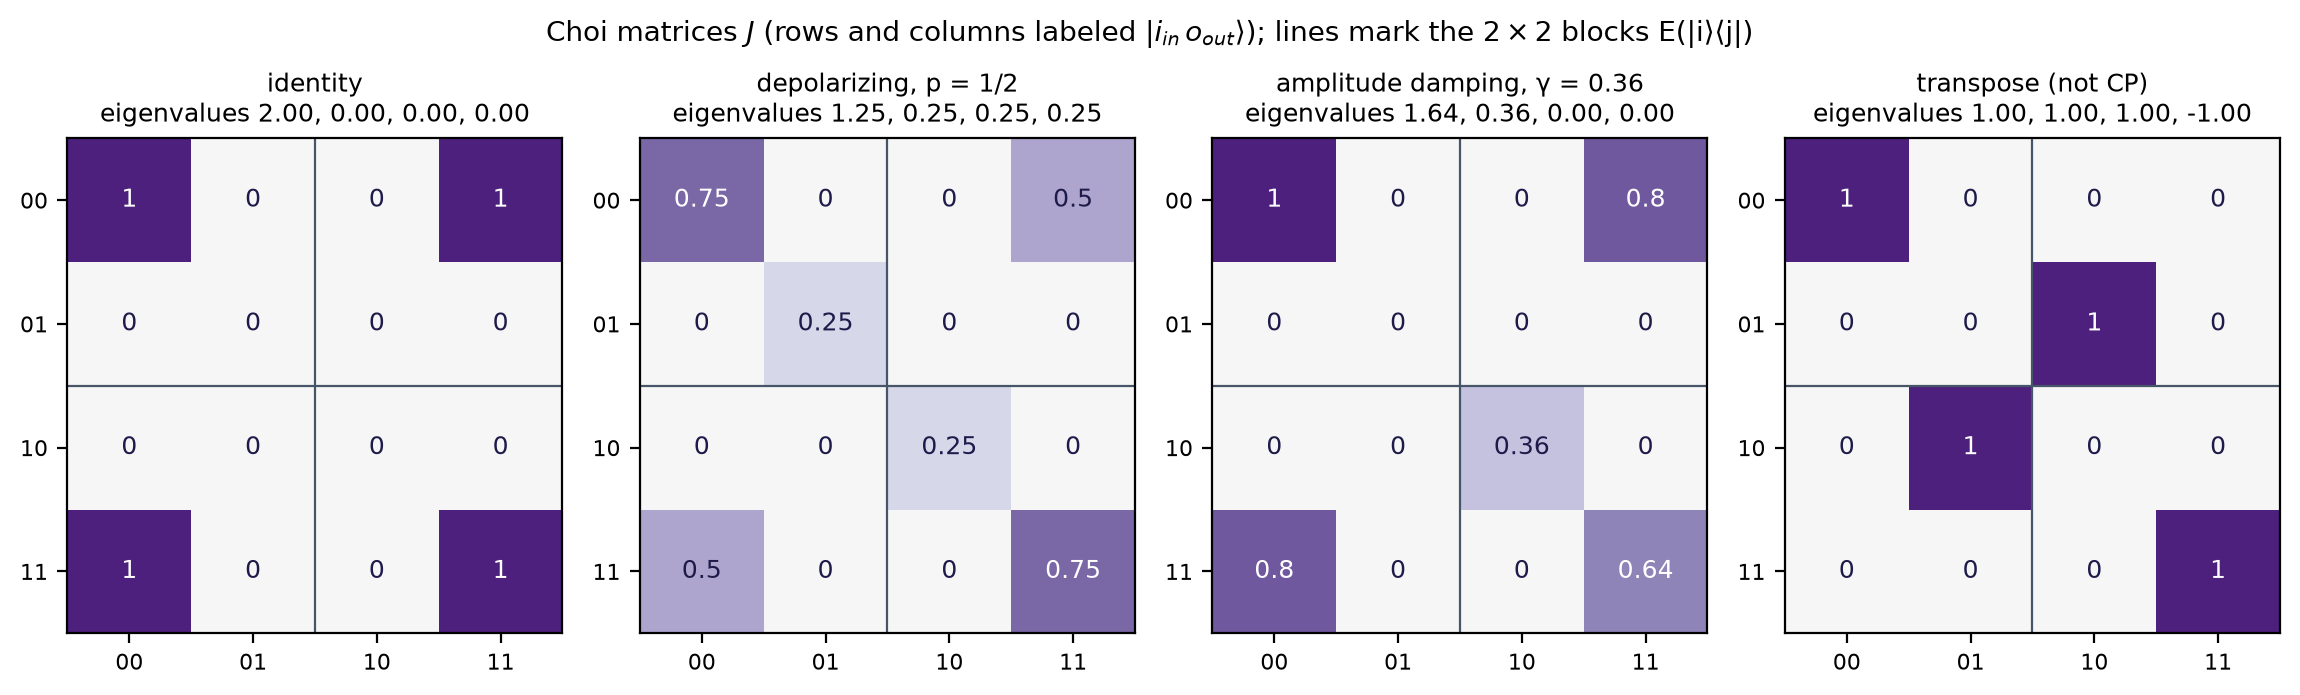

In [3]:
_show_mpl(_lessonfigs.choi_gallery())

*Choi matrices of four qubit maps, with eigenvalues in the titles. The identity has rank 1; depolarizing with $p = 1/2$ and amplitude damping with $\gamma = 0.36$ are positive semidefinite with trace 2; the transpose has the right partial trace but eigenvalue $-1$.*

## Compute it

Build the Choi matrix of amplitude damping with $\gamma = 0.36$, check $\operatorname{Tr}_{\mathrm{out}} J = I$ and the eigenvalues, and recover the output for the complex state $|{+i}\rangle$ with and without the transpose.


In [4]:
import numpy as np
from qcai import science as s

def choi_of(E, d=2):
    """J = sum_ij |i><j| (x) E(|i><j|): input factor first, output second, unnormalized."""
    J = 0
    for i in range(d):
        for j in range(d):
            Eij = np.zeros((d, d), dtype=complex)
            Eij[i, j] = 1
            J = J + np.kron(Eij, E(Eij))   # shape (d * d_out, d * d_out)
    return J

def tr_in(M, din, dout):          # partial trace over the first (input) factor
    return np.einsum('aiaj->ij', M.reshape(din, dout, din, dout))

def tr_out(M, din, dout):         # partial trace over the second (output) factor
    return np.einsum('iaja->ij', M.reshape(din, dout, din, dout))

def recover(J, rho):
    """E(rho) = Tr_in[(rho^T (x) I) J]; the transpose is taken in the basis used to build J."""
    din = rho.shape[0]
    dout = J.shape[0] // din
    return tr_in(np.kron(rho.T, np.eye(dout)) @ J, din, dout)

gamma = 0.36
K = s.amplitude_damping_kraus(gamma)
J = s.choi(K)                      # the course package uses the same convention
assert np.allclose(J, choi_of(lambda X: s.apply_kraus(X, K)))
print(np.round(J.real, 3))
print('eigenvalues of J:', np.round(np.sort(np.linalg.eigvalsh(J))[::-1], 4))
print('Tr_out J =', np.round(tr_out(J, 2, 2).real, 12).tolist(), ' Tr J =', round(np.trace(J).real, 12))

rho = s.dm(np.array([1, 1j]) / np.sqrt(2))       # |+i>: complex off-diagonal entries
out = recover(J, rho)
assert np.allclose(out, s.apply_kraus(rho, K))
print('E(|+i><+i|) =', np.round(out, 4).tolist(), ' Bloch vector', np.round(s.bloch(out), 4))
wrong = tr_in(np.kron(rho, np.eye(2)) @ J, 2, 2)  # the transpose forgotten
print('without the transpose: Bloch vector', np.round(s.bloch(wrong), 4))

[[1.   0.   0.   0.8 ]
 [0.   0.   0.   0.  ]
 [0.   0.   0.36 0.  ]
 [0.8  0.   0.   0.64]]
eigenvalues of J: [1.64 0.36 0.   0.  ]
Tr_out J = [[1.0, 0.0], [0.0, 1.0]]  Tr J = 2.0
E(|+i><+i|) = [[(0.68+0j), -0.4j], [0.4j, (0.32+0j)]]  Bloch vector [0.   0.8  0.36]
without the transpose: Bloch vector [ 0.   -0.8   0.36]


Random channels (here from a qubit to a qutrit) tested on random complex inputs, Kraus operators read off the eigenvectors of $J$, the transpose map, and the family $\mathcal{E}_p$ beyond its physical range.


In [5]:
rng = np.random.default_rng(7)

def random_channel(din, dout, m):
    """Kraus operators of a random channel from a random isometry C^din -> C^dout (x) C^m."""
    G = rng.normal(size=(dout * m, din)) + 1j * rng.normal(size=(dout * m, din))
    V = np.linalg.qr(G)[0].reshape(dout, m, din)
    return [V[:, k, :] for k in range(m)]

def is_cp(J, tol=1e-10):
    return bool(np.linalg.eigvalsh(J).min() > -tol)

def is_tp(J, din, dout):
    return bool(np.allclose(tr_out(J, din, dout), np.eye(din)))

# a random channel from a qubit to a qutrit, tested on a random complex input state
Kr = random_channel(2, 3, 2)
Jr = choi_of(lambda X: sum(k @ X @ k.conj().T for k in Kr))
G = rng.normal(size=(2, 2)) + 1j * rng.normal(size=(2, 2))
rho = G @ G.conj().T / np.trace(G @ G.conj().T)
direct = sum(k @ rho @ k.conj().T for k in Kr)
print('random channel: CP', is_cp(Jr), ' TP', is_tp(Jr, 2, 3), ' Tr J =', round(np.trace(Jr).real, 10))
print('recovery error', float(np.abs(recover(Jr, rho) - direct).max()))

# Kraus operators from the eigenvectors of J: (I (x) K)|Omega> = v, so K = v.reshape(din, dout).T
w, V = np.linalg.eigh(Jr)
Ks = [np.sqrt(wk) * V[:, k].reshape(2, 3).T for k, wk in enumerate(w) if wk > 1e-10]
print('rank of J =', len(Ks), ' Kraus completeness', np.allclose(sum(k.conj().T @ k for k in Ks), np.eye(2)))
assert np.allclose(sum(k @ rho @ k.conj().T for k in Ks), direct)

# the transpose map: trace preserving and positive, but J = SWAP has eigenvalue -1
JT = choi_of(lambda X: X.T)
print('transpose: CP', is_cp(JT), ' TP', is_tp(JT, 2, 2), ' eigenvalues', np.round(np.linalg.eigvalsh(JT), 6))

# rho -> (1 - p) rho + p Tr(rho) I/2 for p beyond [0, 1]: eigenvalues 2 - 3p/2 and p/2 (three times)
for p in (0.0, 0.5, 1.0, 4 / 3, 1.5):
    Jp = choi_of(lambda X: (1 - p) * X + p * np.trace(X) * np.eye(2) / 2)
    ev = np.sort(np.linalg.eigvalsh(Jp))[::-1]
    assert np.allclose(ev, sorted([2 - 1.5 * p, p / 2, p / 2, p / 2], reverse=True))
    print(f'p = {p:.3f}: eigenvalues {np.round(ev, 4)}  CP {is_cp(Jp)}')

random channel: CP True  TP True  Tr J = 2.0
recovery error 6.206335383118183e-17
rank of J = 2  Kraus completeness True
transpose: CP False  TP True  eigenvalues [-1.  1.  1.  1.]
p = 0.000: eigenvalues [2. 0. 0. 0.]  CP True
p = 0.500: eigenvalues [1.25 0.25 0.25 0.25]  CP True
p = 1.000: eigenvalues [0.5 0.5 0.5 0.5]  CP True
p = 1.333: eigenvalues [0.6667 0.6667 0.6667 0.    ]  CP True
p = 1.500: eigenvalues [ 0.75  0.75  0.75 -0.25]  CP False


The link product composes two random channels, $\mathcal{E}$ from a qubit to a qutrit and $\mathcal{F}$ back; leaving out the partial transpose gives the wrong operator.


In [6]:
def pt_out(J, din, dout):          # partial transpose on the output factor
    return J.reshape(din, dout, din, dout).transpose(0, 3, 2, 1).reshape(din * dout, din * dout)

def link(JE, JF, dA, dB, dC):
    """Choi operator of F after E: Tr_B[(JE^{T_B} (x) I_C)(I_A (x) JF)]."""
    M = np.kron(pt_out(JE, dA, dB), np.eye(dC)) @ np.kron(np.eye(dA), JF)
    return np.einsum('abcdbe->acde', M.reshape(dA, dB, dC, dA, dB, dC)).reshape(dA * dC, dA * dC)

KE, KF = random_channel(2, 3, 2), random_channel(3, 2, 2)
E = lambda X: sum(k @ X @ k.conj().T for k in KE)
F = lambda X: sum(k @ X @ k.conj().T for k in KF)
JE, JF = choi_of(E, 2), choi_of(F, 3)
J_FE = choi_of(lambda X: F(E(X)), 2)
print('link product error      ', float(np.abs(link(JE, JF, 2, 3, 2) - J_FE).max()))
naive = np.einsum('abcdbe->acde', (np.kron(JE, np.eye(2)) @ np.kron(np.eye(2), JF)).reshape(2, 3, 2, 2, 3, 2)).reshape(4, 4)
print('without the partial transpose', float(np.abs(naive - J_FE).max()))

link product error       1.1159342773238595e-16
without the partial transpose 0.47070773592611365


## Worked example

:::{admonition} Recovering an amplitude-damped $|{+i}\rangle$
:class: tip

Amplitude damping with $\gamma = 0.36$ acts on $\rho = |{+i}\rangle\langle{+i}|$, $|{+i}\rangle = (|0\rangle + i|1\rangle)/\sqrt{2}$. Use the Choi matrix to find $\mathcal{E}(\rho)$ and its Bloch vector, and find what the formula without the transpose would predict.

1. In the computational basis $\rho = \tfrac12\begin{pmatrix} 1 & -i \\ i & 1 \end{pmatrix}$, so $\rho_{00} = \rho_{11} = 1/2$, $\rho_{01} = -i/2$, $\rho_{10} = i/2$, and $\rho^{T} = \tfrac12\begin{pmatrix} 1 & i \\ -i & 1 \end{pmatrix}$.
2. The recovery formula gives $\mathcal{E}(\rho) = \sum_{i,j} \rho_{ij}\, \mathcal{E}(|i\rangle\langle j|)$ with the blocks of $J$: $\tfrac12 |0\rangle\langle 0| - \tfrac{i}{2}(0.8)|0\rangle\langle 1| + \tfrac{i}{2}(0.8)|1\rangle\langle 0| + \tfrac12(0.36|0\rangle\langle 0| + 0.64|1\rangle\langle 1|)$.
3. Collect terms: $\mathcal{E}(\rho) = \begin{pmatrix} 0.68 & -0.4i \\ 0.4i & 0.32 \end{pmatrix}$, trace 1 as trace preservation requires. With $\rho_{01} = (x - iy)/2$ and $z = \rho_{00} - \rho_{11}$, the Bloch vector is $(0, 0.8, 0.36)$: the $y$ component shrinks by $\sqrt{1-\gamma} = 0.8$ and the state drifts toward $|0\rangle$ by $\gamma = 0.36$.
4. Dropping the transpose computes $\mathcal{E}(\rho^{T}) = \begin{pmatrix} 0.68 & 0.4i \\ -0.4i & 0.32 \end{pmatrix}$, Bloch vector $(0, -0.8, 0.36)$: the wrong hemisphere in $y$, even though trace, positivity and the $z$ coordinate all look fine.

**Result.** $\mathcal{E}(|{+i}\rangle\langle{+i}|)$ has Bloch vector $(0, 0.8, 0.36)$; the transpose-free formula gives $(0, -0.8, 0.36)$, an error no sanity check on trace or positivity would catch.
:::

## Exercises

**1. (Core)** A replacement channel outputs a fixed qubit state $\sigma$ for every input: $\mathcal{R}(X) = \operatorname{Tr}(X)\,\sigma$. Write $J_{\mathcal{R}}$, check both of Choi's tests, and recover $\mathcal{R}(\rho)$ from it.

:::{dropdown} Solution
$J_{\mathcal{R}} = \sum_{i,j} |i\rangle\langle j| \otimes \operatorname{Tr}(|i\rangle\langle j|)\sigma = \sum_i |i\rangle\langle i| \otimes \sigma = I \otimes \sigma$. It is positive semidefinite because $\sigma \succeq 0$ (eigenvalues of $I \otimes \sigma$ are those of $\sigma$, each twice). $\operatorname{Tr}_{\mathrm{out}} J = I\operatorname{Tr}\sigma = I$, so it is TP. Recovery: $\operatorname{Tr}_{\mathrm{in}}[(\rho^{T} \otimes I)(I \otimes \sigma)] = \operatorname{Tr}(\rho^{T})\sigma = \sigma$ for a state.
:::

**2. (Core)** The dephasing channel of the course is $\mathcal{D}_p(\rho) = (1 - p/2)\rho + (p/2) Z\rho Z$. Write $J$ in the basis $|00\rangle, |01\rangle, |10\rangle, |11\rangle$, find its eigenvalues, and give the range of $p$ for which $\mathcal{D}_p$ is CP.

:::{dropdown} Solution
$\mathcal{D}_p$ keeps diagonal entries and multiplies off-diagonal entries by $(1 - p/2) - p/2 = 1 - p$. So $\mathcal{D}_p(|0\rangle\langle 0|) = |0\rangle\langle 0|$, $\mathcal{D}_p(|1\rangle\langle 1|) = |1\rangle\langle 1|$, $\mathcal{D}_p(|0\rangle\langle 1|) = (1-p)|0\rangle\langle 1|$, and $J$ has entries $J_{00,00} = J_{11,11} = 1$, $J_{00,11} = J_{11,00} = 1 - p$, all others 0. Eigenvalues: $1 \pm (1-p)$, that is $2 - p$ and $p$, plus $0, 0$. CP if and only if $0 \le p \le 2$; the course uses $p \in [0, 1]$, and $p = 2$ is the unitary $Z$.
:::

**3. (Stretch)** Show that for every linear map, $J_{\mathcal{E}}/d_{\mathrm{in}} = (\mathrm{id} \otimes \mathcal{E})(|\Phi\rangle\langle\Phi|)$ with the normalized $|\Phi\rangle = |\Omega\rangle/\sqrt{d_{\mathrm{in}}}$, and that for a channel this is a density operator whose reduced state on the input factor is $I/d_{\mathrm{in}}$.

:::{dropdown} Solution
$|\Phi\rangle\langle\Phi| = |\Omega\rangle\langle\Omega|/d_{\mathrm{in}}$ and $\mathrm{id} \otimes \mathcal{E}$ is linear, which gives the first identity. For a channel, $J \succeq 0$ by Choi's criterion and $\operatorname{Tr}_{\mathrm{out}} J = I$, so $\operatorname{Tr}(J/d_{\mathrm{in}}) = \operatorname{Tr} I / d_{\mathrm{in}} = 1$ and the input marginal is $\operatorname{Tr}_{\mathrm{out}}(J)/d_{\mathrm{in}} = I/d_{\mathrm{in}}$. So the Choi state is a density operator whose input half is maximally mixed, as it must be, since the channel never touched that half.
:::

**4. (Stretch)** The qubit map $\mathcal{N}(\rho) = \operatorname{Tr}(\rho) I - \rho$ sends the Bloch vector $\vec r$ to $-\vec r$. Show that it is positive and trace preserving, compute the eigenvalues of $J_{\mathcal{N}}$, and find the largest $s$ for which $\vec r \mapsto -s\vec r$ is a channel.

:::{dropdown} Solution
For a state, $I - \rho = \tfrac12(I - \vec r \cdot \vec\sigma)$ is the state with Bloch vector $-\vec r$, so $\mathcal{N}$ is positive, and $\operatorname{Tr}(I - \rho) = 2 - 1 = 1$. $J_{\mathcal{N}} = I \otimes I - |\Omega\rangle\langle\Omega|$, with eigenvalue $1 - 2 = -1$ on $|\Omega\rangle$ and $1$ on its three-dimensional orthogonal complement, so it is not CP. The map $\vec r \mapsto -s\vec r$ is $\mathcal{E}_p$ with $1 - p = -s$; by [](#eq-l6-02-depol) it is CP exactly when $p \le 4/3$, that is $s \le 1/3$. (Equivalently it is the Pauli map with $\lambda = (-s, -s, -s)$, whose weight $p_0 = (1 - 3s)/4$ must be non-negative.)
:::

**5. (Challenge)** Prove that a linear map $\mathcal{E}$ on qubits is completely positive as soon as $\mathrm{id}_2 \otimes \mathcal{E}$ is positive; that is, a qubit-sized ancilla suffices to detect any failure of complete positivity of a map with qubit input. Then use the transpose map to show that positivity alone ($\mathrm{id}_1 \otimes \mathcal{E}$ positive) does not suffice.

:::{dropdown} Solution
If $\mathrm{id}_2 \otimes \mathcal{E}$ is positive, apply it to the positive operator $|\Omega\rangle\langle\Omega|$ on $\mathbb{C}^2 \otimes \mathbb{C}^2$: the result is $J_{\mathcal{E}} \succeq 0$. By Choi's criterion (part 1, the if direction, which built Kraus operators from $J$) $\mathcal{E}$ has a Kraus form and so $\mathrm{id}_k \otimes \mathcal{E}$ is positive for every $k$. The same argument works with ancilla dimension $d_{\mathrm{in}}$ for any input dimension. For the transpose map $T$, $T(\rho) = \rho^{T}$ has the same eigenvalues as $\rho$, so $T$ is positive; but $(\mathrm{id}_2 \otimes T)(|\Omega\rangle\langle\Omega|) = J_T = \mathrm{SWAP}$ has eigenvalue $-1$ on $|01\rangle - |10\rangle$. Normalized: the partial transpose of $|\Phi^+\rangle\langle\Phi^+|$ has eigenvalue $-1/2$.
:::

**6. (Challenge)** Barrett et al. write $\rho_{B|A} = \sum_{i,j} \mathcal{E}(|i\rangle\langle j|) \otimes |i\rangle_{A^*}\langle j|$ and $\mathcal{E}(\rho_A) = \operatorname{Tr}_{AA^*}[\tau^{\mathrm{id}}_A\,\rho_{B|A}\,\rho_A]$ with $\tau^{\mathrm{id}}_A = \sum_{l,m} |l\rangle_{A^*}\langle m| \otimes |l\rangle_A\langle m|$ (identity operators on the missing factors understood). Treating $A^*$ as a second copy of $\mathbb{C}^d$ with the same basis, verify their recovery formula directly and state how their matrix relates to the course's $J$.

:::{dropdown} Solution
The product of one term of each factor is $\mathcal{E}(|i\rangle\langle j|)_B \otimes (|l\rangle\langle m|\,|i\rangle\langle j|)_{A^*} \otimes (|l\rangle\langle m|\,\rho)_A$. The trace over $A^*$ gives $\langle j|l\rangle\langle m|i\rangle = \delta_{jl}\delta_{mi}$, and the trace over $A$ gives $\langle m|\rho|l\rangle = \langle i|\rho|j\rangle = \rho_{ij}$. Summing, $\sum_{i,j} \rho_{ij}\, \mathcal{E}(|i\rangle\langle j|) = \mathcal{E}(\rho)$, with no explicit transpose: the linking operator contracts the indices in the order that our $\rho^{T}$ achieves. As matrices in a fixed basis, $\rho_{B|A} = \mathrm{SWAP}\, J_{\mathcal{E}}\, \mathrm{SWAP}$ (same entries, output factor first), and their normalization $\operatorname{Tr}_B \rho_{B|A} = I$ is our $\operatorname{Tr}_{\mathrm{out}} J = I$.
:::

## Check your understanding

**1. What is the trace of the Choi operator of a qubit channel in the course convention?**

- **A.** 1
- **B.** 1/2
- **C.** 2
- **D.** It depends on the channel

:::{dropdown} Show the answer
**C. 2**

Trace preservation gives $\operatorname{Tr}_{\mathrm{out}} J = I_{\mathrm{in}}$, and the trace of the $2 \times 2$ identity is 2. The Choi state $J/2$ has trace 1.
:::

**2. A qubit map is trace preserving and sends every state to a state. Its Choi operator has eigenvalues $1, 1, 1, -1$. What follows?**

- **A.** It cannot be trace preserving
- **B.** It is positive but not completely positive, so no device implements it
- **C.** It is completely positive but not positive
- **D.** It is a valid channel because it maps states to states

:::{dropdown} Show the answer
**B. It is positive but not completely positive, so no device implements it**

Choi's criterion: a negative eigenvalue of $J$ means the map is not completely positive, so acting on half of an entangled pair it would produce a non-positive operator. The transpose map is exactly this case.
:::

**3. In the course convention, which expression gives $\mathcal{E}(\rho)$?**

- **A.** $\operatorname{Tr}[\rho J]$
- **B.** $\operatorname{Tr}_{\mathrm{in}}[(\rho^{T} \otimes I)J]$
- **C.** $\operatorname{Tr}_{\mathrm{out}}[(I \otimes \rho)J]$
- **D.** $\operatorname{Tr}_{\mathrm{in}}[(\rho \otimes I)J]$

:::{dropdown} Show the answer
**B. $\operatorname{Tr}_{\mathrm{in}}[(\rho^{T} \otimes I)J]$**

The term $|i\rangle\langle j| \otimes \mathcal{E}(|i\rangle\langle j|)$ must be weighted by $\rho_{ij} = \langle j|\rho^{T}|i\rangle$. Without the transpose the formula returns $\mathcal{E}(\rho^{T})$, which differs whenever $\rho$ has a $\sigma_y$ component.
:::

**4. Kraus operators $\{K_k\}$ define a trace-preserving map exactly when which condition holds?** *(Review of [L5-06](#lesson-l5-06))*

- **A.** $\sum_k K_k K_k^{\dagger} = I$
- **B.** $\sum_k K_k = I$
- **C.** $\sum_k K_k^{\dagger} K_k = I$
- **D.** Each $K_k$ is unitary

:::{dropdown} Show the answer
**C. $\sum_k K_k^{\dagger} K_k = I$**

$\operatorname{Tr}\sum_k K_k \rho K_k^{\dagger} = \operatorname{Tr}[(\sum_k K_k^{\dagger}K_k)\rho]$ equals $\operatorname{Tr}\rho$ for all $\rho$ exactly when $\sum_k K_k^{\dagger}K_k = I$. In Choi form this is $\operatorname{Tr}_{\mathrm{out}} J = I$. The other sum, $\sum_k K_k K_k^{\dagger} = I$, is the condition for the map to be unital.
:::

## Common misconceptions

- **"A map that sends every density operator to a density operator is a valid quantum channel."** That is positivity. A channel must stay positive when it acts on part of a larger system. The transpose map and the universal NOT are positive and trace preserving, yet their Choi operators have eigenvalue $-1$.
- **"The Choi operator is a quantum state, so its trace is 1."** In this course $J$ is unnormalized and has trace $d_{\mathrm{in}}$ (2 for a qubit). The Choi state $J/d_{\mathrm{in}}$ has trace 1. Mixing the two conventions puts wrong factors of $d$ into recovered outputs.
- **"The transpose in the recovery formula is a harmless convention that can be dropped for intuition."** Dropping it computes $\mathcal{E}(\rho^{T})$ instead of $\mathcal{E}(\rho)$. For states with a $\sigma_y$ component the prediction lands in the wrong hemisphere of the Bloch ball, while trace and positivity still look correct.

:::{caution} Scope and limits
Every formula here assumes finite dimensions and a fixed orthonormal basis for the transpose; $J$ itself depends on that basis (the Allen and Barrett dual-space version does not). Conventions differ between sources in factor order, normalization and the placement of transposes; translate before combining formulas. Choi's criterion certifies that a map is a mathematically valid channel; it says nothing about how hard the channel is to implement, and estimating $J$ from data (process tomography) adds statistical error that this lesson ignores.
:::

:::{seealso} Where this leads
The Choi operator is the conditional operator $\rho_{B|A}$ of quantum causal models: [L6-01](#lesson-l6-01) used it to state the quantum Reichenbach principle, [L6-03](#lesson-l6-03) multiplies such operators into a process operator, and [L6-07](#lesson-l6-07) asks which operators on many input and output spaces are valid processes. The link product is how networks of channels, including the quantum switch of [L6-08](#lesson-l6-08), are composed.
:::

:::{dropdown} For instructors

**Why this lesson.** Students meet channels through Kraus operators, which hide the convex and spectral structure that later lessons need. The Choi operator turns physicality into linear algebra, and its conventions are exactly where graduate students make silent errors when they combine papers [@watrous; @nielsenchuang; @chiribella].

**Teaching notes.**

- Have students compute $J$ for amplitude damping by hand before running code; the zero row and column (the $|01\rangle$ entry) show that $|0\rangle$ never decays to $|1\rangle$.
- Use $|{+i}\rangle$, not $|+\rangle$, in every recovery check. Real symmetric test states hide a missing transpose; ask students why.
- The family $\mathcal{E}_p$ for $p$ in $(4/3, 2]$ is a clean example of positive but not CP maps; pair it with the interactive tetrahedron and ask where the cube and tetrahedron differ.
- Before L6-03, assign the challenge exercise on the Barrett et al. dictionary so that the dual-space notation is familiar.

**Assessment.** The core exercises check construction and the two tests; the second stretch exercise checks that students can separate positivity from complete positivity; the challenge exercises check proof skills and translation between conventions.

**Going further.** Watrous's textbook develops the Choi representation, Kraus and Stinespring forms and their equivalences in full generality [@watrous]. Chiribella, D'Ariano and Perinotti build quantum combs from the link product [@chiribella]. A research extension: write the Choi operator of a channel with memory (two uses sharing an environment) and check which of its marginals are themselves channels.

:::

## References

This lesson draws on [@watrous; @nielsenchuang; @chiribella; @allen; @barrett; @choi1975; @ocb; @process].

**Further reading.**

- [@watrous]: Chapter 2 treats Choi, Kraus and Stinespring representations with full proofs (output-first convention).
- [@chiribella]: The link product and quantum networks built from Choi operators.
- [@barrett]: Section 3 fixes the dual-space Choi convention used in quantum causal models.

**Next:** [L6-03 · Quantum DAGs and Markov assumptions](#lesson-l6-03)
